# CSC 349A Numerical Analysis - Lecture 19 - Composite Quadrature Methods
This section corresponds to sections 21.1.2, 21.2.2, 21.3, and 21.4 of the text.

**Objective** We want the **truncation error $\rightarrow 0$** as the **number of quadrature points $\rightarrow \infty$**.
Note: this does not happen in general as $n$, the order of the interpolating polynomial, $\rightarrow \infty$ (Runge phenomenon).

**Solution:** We use composite (multiple-application) quadrature formulas.

## Trapezoidal rule
**Main idea:** for $m \geq 1$, apply a closed N-C formula (with $n$ small) $m$ times on $[a,b]$. 

**Example:** Trapezoidal rule $(n=1)$ 

For any $m \geq 1$, let $h = \frac{b-a}{m}$, subdivide $[a,b]$ into $m$ subintervals of length $h$, 
and apply the trapezoidal rule on each subinterval. 

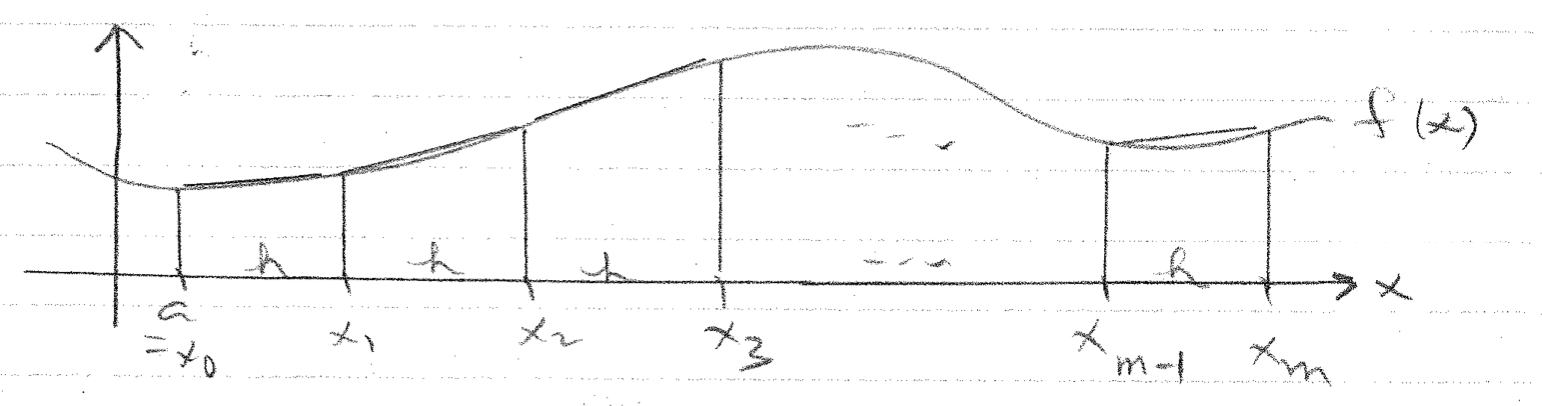

**Composite trapezoidal rule** 

So, we apply the Trapezoidal rule $m$ times using the $m+1$ evenly spaced data points 
$(x_0,f(x_0))$, $(x_1,f(x_1))$, ..., $(x_m,f(x_m))$ where $a=x_0$ and $b=x_m$. That is, 
we linearly interpolate each of the subintervals and integrate usng the resulting interpolating 
polynoimal over each region.

\begin{align*} 
& \int_{a}^{b} f(x)dx = \int_{x_0}^{x_1}f(x)dx +  \int_{x_1}^{x_2}f(x)dx + \dots + \int_{x_{m-1}}^{x_m}f(x)dx \\ 
\approx & \int_{x_0}^{x_1}P_0(x)dx +  \int_{x_1}^{x_2}P_1(x)dx + \dots + \int_{x_{m-1}}^{x_m}P_{m-1}(x)dx \\
=& \frac{h}{2} \left [ f(x_0) + f(x_1) \right ] + \frac{h}{2} \left [ f(x_1) + f(x_2) \right ] + \dots + \frac{h}{2} \left [ f(x_{m-1}) + f(x_{m}) \right ] \\ 
=& \frac{h}{2} \left [ f(x_0) + 2\sum_{i=1}^{m-1} f(x_i) + f(x_m) \right ] 
\end{align*} 

This is called the composite trapezoidal rule. 

**Truncation Error**
\begin{align*} 
E_t =& -\frac{h^3}{12} f''(\xi_1) -\frac{h^3}{12} f''(\xi_2) - \dots - -\frac{h^3}{12} f''(\xi_m)  \\
=& -\frac{h^3}{12} \left [ f''(\xi_1) + f''(\xi_2) + \dots + f''(\xi_m) \right ] 
\end{align*} 
where $x_{i-1} \leq \xi_i \leq x_i$. 

We know that: 
$$
\min_{1 \leq i \leq m} f''(\xi_i) \leq \frac{f''(\xi_1) + f''(\xi_2) + \dots + f''(\xi_m)}{m} \leq \max_{1 \leq i \leq m} f''(\xi_i) 
$$

If $f''(x)$ is continuous on $[a,b]$, then there exists a value $\mu \in [a,b]$ such that: 

$$
f''(\mu) = \frac{f''(\xi_1) + f''(\xi_2) + \dots + f''(\xi_m)}{m} 
$$

This is called the intermediate value theorem. 

$$
E_t = - \frac{h^3}{12} [ m f''(\mu)] = - \frac{(b-a)}{12} h^2 f''(\mu) 
$$

since $h = \frac{b-a}{m}$. 

**Important point** 
$$
\lim_{m \rightarrow \infty} E_t = \lim_{h \rightarrow 0} E_t = 0
$$
provided that $f''(x)$ is continuous on $[a,b]$. 

(there is no comparable result as $n \rightarrow \infty$, where $n$ is the degree of the interpolating polynomial) 

### Example 1
Use the two-segment ($m=2$) trapezoidal rule to estimate the integral of 
$f(x)=0.2+25x-200x^2+675x^3-900x^4+400x^5$ from $a=0$ to $b=0.8$. Recall 
that the correct value for the integral is $\int_0^{0.8} f(x)dx=1.640533$.

**Solution** Here, we need three data points, $f(0)=0.2, f(0.4)=2.456$, 
and $f(0.8)=0.232$. Also, $h=\frac{b-a}{m}=\frac{0.8}{2}=0.4$. Thus,

\begin{align*}
\int_0^{0.8} f(x)dx &\approx \frac{h}{2} \left[f(x_0)+2f(x_1)+f(x_2) \right] \\
&= \frac{0.4}{2}\left[f(0)+2f(0.4)+f(0.8) \right] \\
&= 0.2\left[0.2+2(2.456)+0.232 \right] \\
&=1.0688
\end{align*}

That means $|E_t| = |1.640533 - 1.0688| = 0.57173$.

**Implementation** Usual implementation of composite trapezoidal: 
* Initialize $m=1$ 
* Repeatedly double $m$ (m=1,2,4,8,16,32,\dots )
* Until two consecutive approximations are sufficiently close 

The reason for using these values of $m$ is that they permit re-use of the 
function evaluations from previous evaluations, i.e all values $f(x_i)$ computed 
for $m=k$ can be re-used for $m=2k$. 

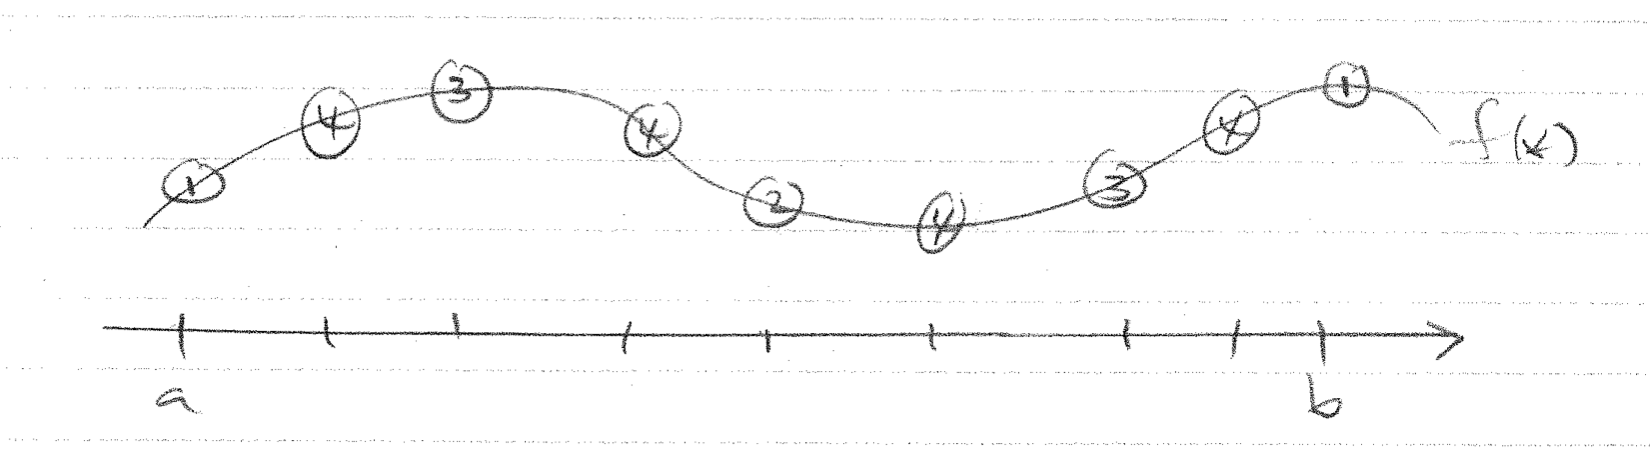

## Composite Simpson's Rule
Each application of Simpson's rule requires 2 subintervals on the interval of 
integration and 3 quadrature points. Thus, $m$ applications of Simpson's rule 
on $[a,b]$ require that $[a,b]$ be subdivided into $2m$ subintervals using $2m+1$ 
quadrature points. Each subinterval then is of length
$$
h=\frac{b-a}{2m}
$$

Thus, at the $jth$ subinterval we have the three quadrature points $x_{2j-2}$, $x_{2j-1}$, 
and $x_{2j}$, and
$$
\int_{x_{2j-2}}^{x_{2j}} f(x)dx \approx \frac{h}{3} \left [ f(x_{2j-2}) + 4f(x_{2j-1}) + f(x_{2j}) \right ] 
$$		     

When $m=1$ (regular Simpson's rule) we have $2(1)+1=3$ quadrature points and 2 subintervals each 
of length $h=\frac{b-a}{2}$.

When $m=2$, we apply Simpson's rule twice. We need $2(2)+1=5$ quadrature points to create $4$ 
subintervals each of length $h=\frac{b-a}{4}$.

Here,
\begin{align*} 
& \int_{a}^{b} f(x)dx \\
& \approx \frac{h}{3} \left [ f(x_0) + 4f(x_1) + f(x_2) \right ] + \frac{h}{3} \left [ f(x_2) + 4f(x_3) + f(x_4) \right ] \\
& = \frac{h}{3} \left [ f(x_0) + 4f(x_1) + 2f(x_2) + 4f(x_3) + f(x_4) \right ]
\end{align*} 

In general, when $m \geq 1$, the composite Simpson's rule approximation is
\begin{align*} 
 \int_{a}^{b} f(x)dx \\
 & \approx \frac{h}{3}  [f(x_0) + 4f(x_1) + 2f(x_2) + 4f(x_3) + 2f(x_4) +  \dotsm + 2f(x_{2m-2}) + 4f(x_{2m-1}) + f(x_{2m})]  \\
& = \frac{h}{3} \left [ f(x_0) + 4\sum_{j=1}^{m}f(x_{2j-1}) + 2\sum_{j=1}^{m-1}f(x_{2j}) + f(x_{2m}) \right ]
\end{align*} 

**Truncation Error**
\begin{align*} 
E_t =& -\frac{h^5}{90} f^{(4)}(\xi_1) -\frac{h^5}{90} f^{(4)}(\xi_2) - \dots - -\frac{h^5}{90} f^{(4)}(\xi_m)  \\
=& -\frac{h^5}{90} \left [ f^{(4)}(\xi_1) + f^{(4)}(\xi_2) + \dots + f^{(4)}(\xi_m) \right ] \\
=& - \frac{h^5}{90} [ m f^{(4)}(\mu)]
\end{align*} 
where $a \leq \mu\leq b$ and $f^{(4)}(x)$ is continous. So,
\begin{align*} 
E_t = -\frac{(b-a)h^4}{180}f^{(4)}(\mu)
\end{align*} 
since $h = \frac{b-a}{2m}$. 

### Example 2
Use the two-segment ($m=2$) composite Simpson's rule to estimate the integral 
of $f(x)=0.2+25x-200x^2+675x^3-900x^4+400x^5$ from $a=0$ to $b=0.8$. Recall that 
the correct value for the integral is $\int_0^{0.8} f(x)dx=1.640533$.

**Solution** Here, we need  five data points, $f(0)=0.2, f(0.2)=1.288,f(0.4)=2.456,f(0.6)=3.464$, 
and $f(0.8)=0.232$. Also, $h=\frac{b-a}{2m}=\frac{0.8}{4}=0.2$. Thus,

\begin{align*}
\int_0^{0.8} f(x)dx &\approx \frac{h}{3} \left[f(x_0)+4f(x_1)+2f(x_2)+4f(x_3)+f(x_4) \right] \\
&= \frac{0.2}{3}\left[f(0)+4f(0.2)+2f(0.4)+4f(0.6)+f(0.8) \right] \\
&= \frac{0.2}{3}\left[0.2+4(1.288)+2(2.456)+4(3.464)+0.232 \right] \\
&=1.623467
\end{align*}

That means $|E_t| = |1.640533 - 1.623467| = 0.017067$.

## Degree of Precision of a Quadrature Formula

The **degree of precision** of a quadrature formula is a measure of its accuracy or power. It is an integer number that indicates the degree (or order) of the set of all polynomials that the quadrature formula will integrate exactly. The larger the degree of precision, the more accurate or powerful is the quadrature formula because it will integrate exactly a larger set of polynomials, and this is a very good indicator that it will therefore integrate non-polynomial functions more accurately.

**Defintion**
If a quadrature formula $\sum_{i=0}^{n} a_i f(x_i)$ computes the exact value of $\int_{a}^{b} f(x)dx$ whenever $f(x)$ is a polynomial of degree $d$, but

$$
\sum_{i=0}^{n} a_i f(x_i) \neq \int_{a}^{b} f(x)dx
$$

for some polynomial $f(x)$ of degree $d+1$, then the **degree of precision** of the quadrature formula is $d$.

*Note:*
If $f(x)$ is a polynomial of degree $d$, then $f(x) = \sum_{i=0}^{d} c_i x^i$ and 

$$
\int_{a}^{b} f(x)dx = \sum_{i=0}^{d} c_i \left [\int_{a}^{b} x^idx \right ]
$$

Consequently, a quadrature formula computes $\int_{a}^{b} f(x)dx$ exactly if and only if it computes each of

$$
\int_{a}^{b} dx, \int_{a}^{b} xdx, ..., \int_{a}^{b} x^ddx
$$

exactly.

**Theorem**
The degree of precision of a quadrature formula is $d$ if and only if the quadrature formula computes the exact value of the integral when

$$
f(x)=1,x,x^2,...,x^d
$$

and it is not exact when $f(x)=x^{d+1}$.

### Example 3
Determine the degree of precision of the trapezoidal rule,

$$
\int_a^b{f(x)dx} \approx \frac{b-a}{2}[f(a)+f(b)]
$$

When $f(x)=1$, i.e. $d=0$, then

$$
\int_a^b{1dx}=\left[x\right]_a^b=b-a
$$

and

$$
\frac{b-a}{2}[f(a)+f(b)] = \frac{b-a}{2}[1+1]=b-a
$$

When $f(x)=x$, i.e. $d=1$, then

$$
\int_a^b{xdx}=\left[\frac{x^2}{2}\right]_a^b=\frac{b^2-a^2}{2}
$$

and

$$
\frac{b-a}{2}[f(a)+f(b)] = \frac{b-a}{2}[a+b]=\frac{ba+b^2-a^2-ab}{2}=\frac{b^2-a^2}{2}
$$

Finally, when $f(x)=x^2$, i.e. $d=2$,

$$
\int_a^b{x^2dx}=\left[\frac{x^3}{3}\right]_a^b=\frac{b^3-a^3}{3}
$$

but

$$
\frac{b-a}{2}[f(a)+f(b)] = \frac{b-a}{2}[a^2+b^2]=\frac{ba^2+b^3-a^3-ab^2}{3} \neq \frac{b^3-a^3}{3}
$$

Therefore, the degree of precision of the trapezoidal rule is $d=1$.

### Another way
The degree of precision is also clear if you know the error term for the quadrature formula. For example, since the error term for the Trapezoidal Rule is $\frac{-h^3}{12}f''(\xi)$, for some value $\xi \in [a,b]$, this error term is exactly equal to 0 if and only if $f''(x)=0$ for all $x \in [a,b]$. This is true if and only if $f(x)=c_0 + c_1x$. That is, the Trapezoidal Rule computes the exact value of the integral of a polynomial $f(x)$ if and only if $f(x)$ is a polynomial of degree $\leq 1$  (that is, the degree of precision is $d=1$).

**Note on the Precision of Simpson's 1/3 Rule:**
The degree of precision $d=3$ for Simpson’s 1/3 rule is larger than expected since it is obtained by integrating a quadratic interpolating polynomial. This means that if $P(x)$ is a quadratic polynomial that interpolates any cubic polynomial

$$
f(x)=c_0 + c_1x + c_2x^2 + c_3x^3
$$

at the points $a$, $b$ and $(a+b)/2$, then

$$
\int_{a}^{b} f(x)dx = \int_{a}^{b} P(x)dx
$$

exactly. This larger-than-expected value of the degree of precision occurs for Newton-Cotes closed quadrature formulas **for all even values of $n$**. This is not so of the odd values of $n$. (Note the error term for the Cubic Quadrature case: $\frac{-3}{80}h^5f^{(4)}(\xi)$.) 

In summary,

| $n$ | degree of precision |
|:--------|:-----------:|
| 1 (trap rule) | 1 | 
| 2 (1/3 rule) | 3 | 
| 3 (3/8 rule) | 3 | 
| 4 | 5 | 
| 5 | 5 | 
| 6 | 7 |